# Численная проверка Linear backward на MPS

Сравниваем градиенты на CPU и MPS. На сохранённом пакете блочный расчёт снизил расхождение до уровня ниже заданного порога.

[Описание главы](README.md)

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Импорт работает и без editable install, если notebook открыт внутри репозитория.
root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'pyproject.toml').is_file() and (p / 'research').is_dir())
if str(root / 'src') not in sys.path:
    sys.path.insert(0, str(root / 'src'))
from recsys_lab.presentation import setup_style, save_figure
from recsys_lab.statistics import paired_bootstrap
from recsys_lab.session import ResearchSession
import os
setup_style()

chapter = root / 'research/appendix_mps'
results = chapter / 'results'
figures = chapter / 'figures'

# saved: результаты первоначального исследования; train: новый рабочий запуск.
MODE = "saved"
RUN_NAME = "reproduction"
RAW_DIR = os.environ.get("T_ECD_RAW")  # Каталог с items.pq и events/.
session = ResearchSession(mode=MODE, run_name=RUN_NAME, raw_dir=RAW_DIR)

def read(name):
    return session.read(chapter.name, name)

registry = pd.read_csv(root / 'results/experiment_registry.csv')

## Градиенты на CPU и MPS

Обе системы получили один и тот же пакет примеров. Для каждого параметра сравниваем максимальную относительную ошибку с порогом 0,001.

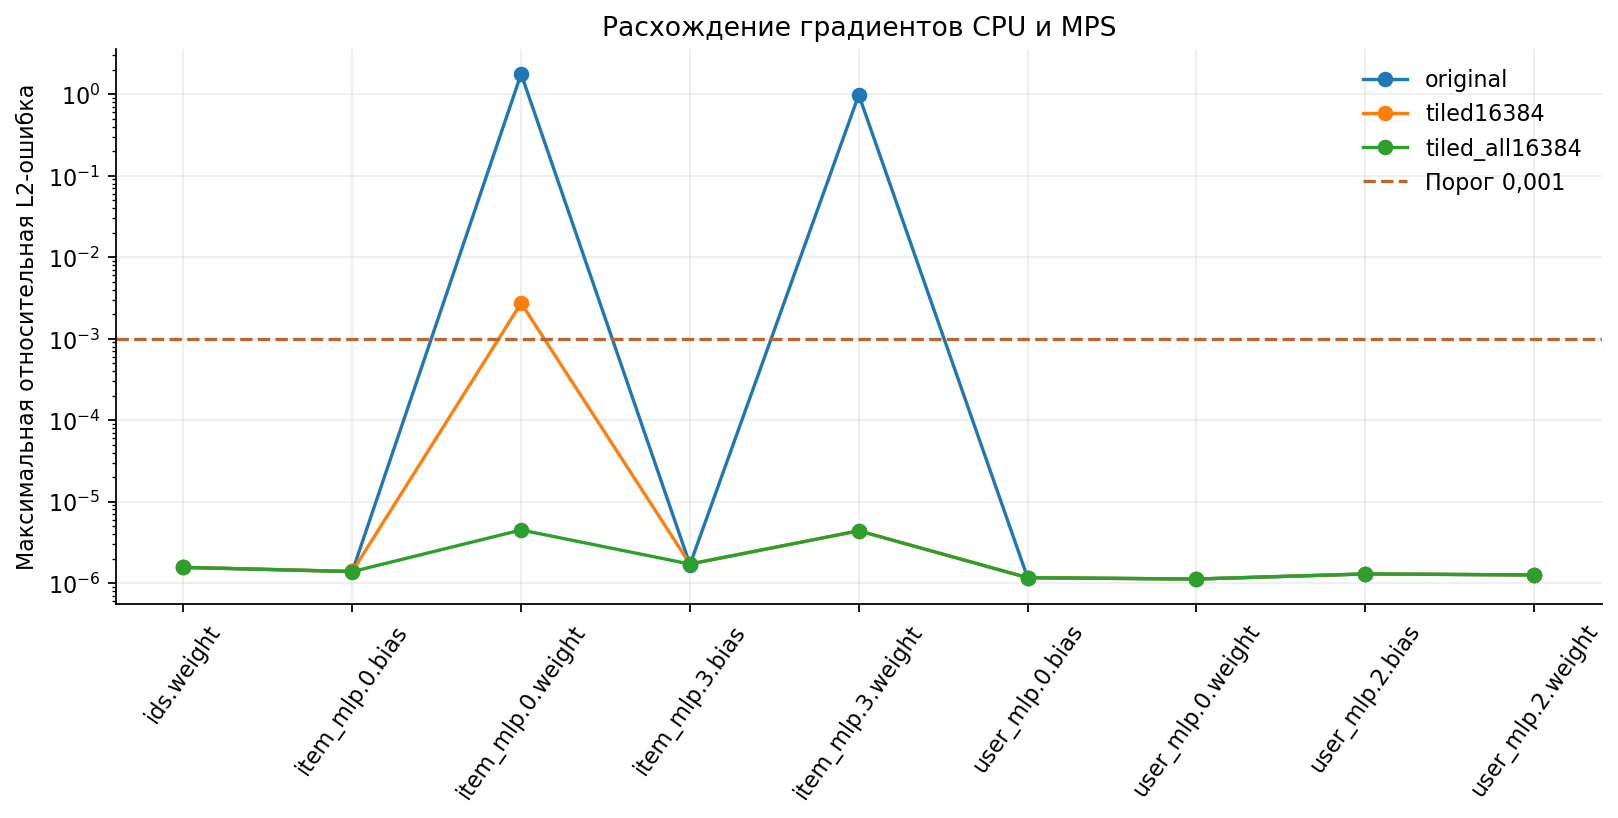

mode,original,tiled16384,tiled_all16384
parameter,,,
ids.weight,0.000002,0.000002,0.000002
item_mlp.0.bias,0.000001,0.000001,0.000001
item_mlp.0.weight,1.778679,0.002731,0.000004
item_mlp.3.bias,0.000002,0.000002,0.000002
item_mlp.3.weight,0.984186,0.000004,0.000004
user_mlp.0.bias,0.000001,0.000001,0.000001
user_mlp.0.weight,0.000001,0.000001,0.000001
user_mlp.2.bias,0.000001,0.000001,0.000001
user_mlp.2.weight,0.000001,0.000001,0.000001


In [2]:
proof = read('stability_lr_20261108__strong_all_seed2026_lr0p0003_8epochs_tiledall16384__all_linear_verification.json')
records=[]
for record in proof['records']:
    for parameter in record['parameters']:
        records.append({'mode':record['mode'],'repeat':record['repeat'],**parameter})
gradients=pd.DataFrame(records)
worst=gradients.groupby(['mode','parameter']).relative_l2.max().unstack(0)
fig,ax=plt.subplots(figsize=(10,5))
for mode in worst.columns:
    ax.plot(np.arange(len(worst)),worst[mode].clip(lower=1e-10),marker='o',label=mode)
ax.axhline(.001,color='#B76832',ls='--',label='Порог 0,001')
ax.set(yscale='log',xticks=np.arange(len(worst)),xticklabels=worst.index,ylabel='Максимальная относительная L2-ошибка',title='Расхождение градиентов CPU и MPS')
ax.tick_params(axis='x',rotation=55)
ax.legend(frameon=False)
save_figure(fig, figures/'gradient_error.png')
plt.show()
display(worst)

## Обновления Adam

Сравниваем размеры обновлений весов и отклонение от эталонного шага Adam.

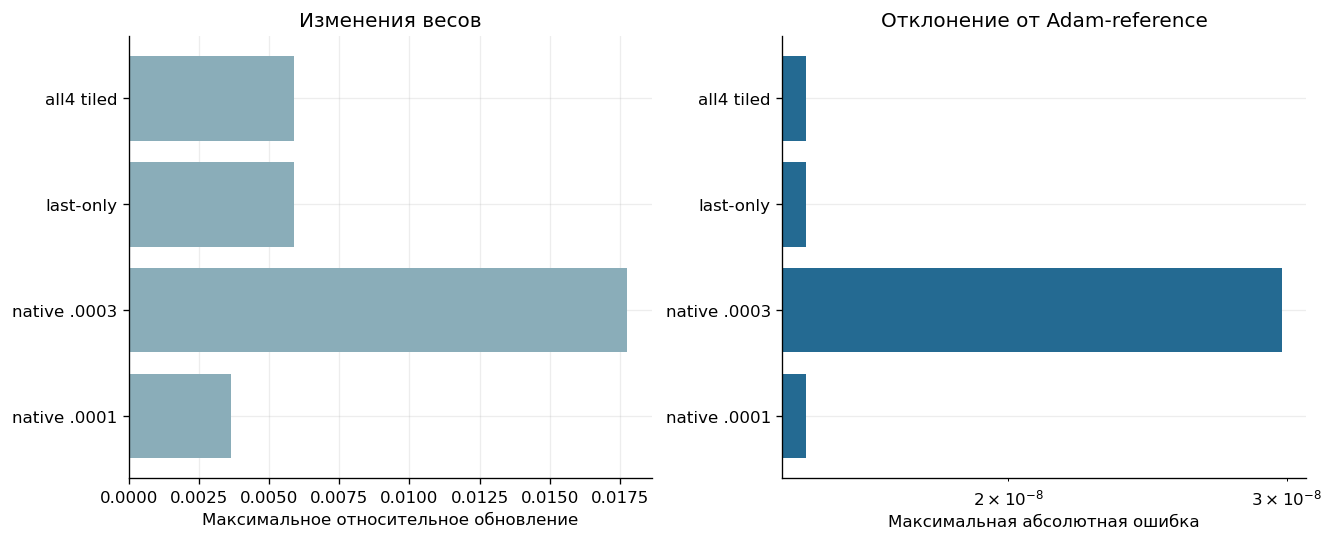

,run,implementation,updates,maximum_preclip_gradient,maximum_postclip_gradient,maximum_critical_weight_norm,maximum_relative_update,maximum_coordinate_update,maximum_adam_reference_error,incident_files,finite
0,strong_all_seed2026_lr0p0001_8epochs_monitored,native,1622,453.637573,1.0,7.745782,0.003647,0.000406,1.490116e-08,0,True
1,strong_all_seed2026_lr0p0003_8epochs_monitored,native,1691,1110.604492,1.0,14.160028,0.017769,0.001728,2.980232e-08,2,True
2,strong_all_seed2026_lr0p0003_8epochs_tiled16384,tiled16384,4500,425.438385,1.0,4.947592,0.005892,0.000431,1.490116e-08,0,True
3,strong_all_seed2026_lr0p0003_8epochs_tiled1638...,tiled16384,5992,434.490021,1.0,5.057623,0.005892,0.000431,1.490116e-08,0,True
4,strong_all_seed2026_lr0p0003_8epochs_tiledall1...,all4_tiled16384,5992,15.251112,1.0,5.057660,0.005892,0.000431,1.490116e-08,0,True


In [3]:
updates=read('stability_lr_20261108__update_summary.csv')
labels=['all4 tiled' if 'tiledall' in x else 'last-only' if 'tiled' in x else 'native .0001' if '0p0001' in x else 'native .0003' for x in updates.run]
fig,axes=plt.subplots(1,2,figsize=(11,4.4))
axes[0].barh(labels,updates.maximum_relative_update,color='#8AADB9')
axes[0].set(xlabel='Максимальное относительное обновление',title='Изменения весов')
axes[1].barh(labels,updates.maximum_adam_reference_error,color='#246A92')
axes[1].set(xlabel='Максимальная абсолютная ошибка',title='Отклонение от Adam-reference',xscale='log')
save_figure(fig, figures/'update_diagnostics.png')
plt.show()
display(updates)

## Проверка производных на CPU

На небольшом входе с точностью float64 проверяем равенство стандартного и блочного расчёта производных. Шаг оптимизатора не выполняется.

In [4]:
import importlib.util
if importlib.util.find_spec('torch') is not None:
    import torch
    from recsys_lab.tiled_linear import _TiledLinear
    torch.manual_seed(2026)
    x=torch.randn(11,5,dtype=torch.float64,requires_grad=True)
    weight=torch.randn(7,5,dtype=torch.float64,requires_grad=True)
    bias=torch.randn(7,dtype=torch.float64,requires_grad=True)
    g=torch.randn(11,7,dtype=torch.float64)
    native=torch.nn.functional.linear(x,weight,bias)
    tiled=_TiledLinear.apply(x,weight,bias,4)
    grad_native=torch.autograd.grad(native,(x,weight,bias),g,retain_graph=True)
    grad_tiled=torch.autograd.grad(tiled,(x,weight,bias),g)
    errors=[float((a-b).abs().max()) for a,b in zip(grad_native,grad_tiled)]
    assert torch.allclose(native,tiled,atol=1e-12,rtol=1e-12)
    assert max(errors)<1e-12
    print('CPU float64 derivative errors:',errors)
else:
    print('Пропуск численного теста: для него установите .[training]. Сохранённые CPU/MPS evidence прочитаны выше.')

CPU float64 derivative errors: [0.0, 8.881784197001252e-16, 8.881784197001252e-16]


## Необязательная проверка на MPS

Выключенная по умолчанию проверка на небольшом примере. Обучение не запускается.

In [5]:
RUN_MPS_CHECK=False
if RUN_MPS_CHECK:
    import torch
    from recsys_lab.tiled_linear import _TiledLinear
    assert torch.backends.mps.is_available(), 'MPS required'
    torch.manual_seed(2026)
    values=[torch.randn(1024,64),torch.randn(128,64),torch.randn(128)]
    cpu=[v.clone().requires_grad_() for v in values]
    mps=[v.to('mps').requires_grad_() for v in values]
    output_gradient=torch.randn(1024,128)
    cpu_y=torch.nn.functional.linear(*cpu)
    mps_y=_TiledLinear.apply(*mps,16384)
    a=torch.autograd.grad(cpu_y,cpu,output_gradient)
    b=torch.autograd.grad(mps_y,mps,output_gradient.to('mps'))
    print('Small-batch relative errors:',[float((x-y.cpu()).norm()/x.norm().clamp_min(1e-12)) for x,y in zip(a,b)])

## Вывод

При блочном расчёте ошибка градиентов на сохранённом пакете оказалась ниже порога 0,001. С этим расчётом модель прошла восемь эпох. Причина расхождения стандартного расчёта не установлена.